In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 230.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 369.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 367.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 325.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 375.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 333.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 287.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 340.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 289.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 296.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 304.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
import re
import difflib
from collections import Counter
from typing import List, Dict

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


import torch
from peft import PeftModel
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer, 
    GenerationConfig
)

os.environ["TRANSFORMERS_VERBOSITY"] = "error"

2025-12-30 09:50:54.447441: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767088254.668817      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767088254.734045      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-classification-training-v2-0/qwen2.5-1_5b-gencls-lora/"

MAX_NEW_TOKENS = 6
DO_SAMPLE = False

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=False, trust_remote_code=True)
tmpl_path = os.path.join(ADAPTER_DIR, "chat_template.jinja")
if os.path.exists(tmpl_path):
    with open(tmpl_path, "r", encoding="utf-8") as f:
        tokenizer.chat_template = f.read()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

use_bf16 = torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8
dtype = torch.bfloat16 if use_bf16 else torch.float16

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
model.generation_config = GenerationConfig(
    do_sample=False,
    max_new_tokens=MAX_NEW_TOKENS,
    pad_token_id=tokenizer.eos_token_id,
    eos_token_id=tokenizer.eos_token_id,
)
model.eval()
model.config.use_cache = True

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [5]:
DATA_PATH = "/kaggle/input/new-roles-datasets/Cleaned/instructions.csv"

df = pd.read_csv(DATA_PATH)

train_df, vt = train_test_split(
    df, test_size=0.2, random_state=42, shuffle=True,
    stratify=df["role"] if df["role"].nunique() > 1 else None
)

val_df, test_df = train_test_split(
    vt, test_size=0.5, random_state=42, shuffle=True,
    stratify=vt["role"] if vt["role"].nunique() > 1 else None
)

df = test_df.copy()

if "clean_data" in df.columns:
    df.rename(columns={"clean_data": "text"}, inplace=True)

df = df.dropna(subset=["text", "role"])
df = df[df["role"] != "empty"].reset_index(drop=True)

df["text"] = df["text"].astype(str).str.strip()
df["role"] = df["role"].astype(str).str.strip()

print(f"Loaded {len(df)} rows.")
display(df.head(3))

Loaded 1895 rows.


,role,text
0,Shrek,i became a recluse in the swamp because i was ...
1,Gaston,i was raised in a small village where hunting ...
2,Juno MacGuff,"they were [NAME] and [NAME] [NAME] , and they ..."


In [6]:
global_options = sorted(df["role"].unique().tolist())

SYSTEM_PROMPT = (
    "You are a careful classifier. Choose exactly ONE label from the provided options. "
    "Return ONLY the label text with no extra words."
)

def format_prompt(utterance: str, options: List[str]) -> List[Dict[str, str]]:
    opts_str = ", ".join(options)
    user_content = (
        "Classify the following text by choosing exactly ONE label from the options.\n\n"
        f"Options: {opts_str}\n\n"
        f'Text:\n"""{utterance}"""\n\n'
        "Return ONLY one label from the Options."
    )
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]

def _norm(s: str) -> str:
    return re.sub(r"\s+", " ", s.strip()).lower()

def pick_from_options(generated: str, options: list[str]) -> str:
    g = _norm(generated)
    norm_opts = [(o, _norm(o)) for o in options]

    for o, on in norm_opts:
        if on == g:
            return o

    token_matches = [
        o for o, on in norm_opts
        if re.search(rf'\b{re.escape(on)}\b', g)
    ]
    if token_matches:
        return max(token_matches, key=lambda x: len(_norm(x)))

    rev_matches = [
        o for o, on in norm_opts
        if g and re.search(rf'\b{re.escape(g)}\b', on)
    ]
    if rev_matches:
        return max(rev_matches, key=lambda x: len(_norm(x)))

    return max(options, key=lambda o: difflib.SequenceMatcher(None, _norm(o), g).ratio())

def predict_one(utterance: str) -> str:
    messages = format_prompt(utterance, global_options)

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    gen_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    text = text.splitlines()[0].strip()
    text = re.sub(r'[\s:,\.;\-]+$', '', text)

    return pick_from_options(text, global_options)

In [7]:
tqdm.pandas(desc="Predicting (gen-class)")
df["pred"] = df["text"].progress_apply(predict_one)

def normalize_role(s):
    return str(s).strip().lower()

df["role_norm"] = df["role"].apply(normalize_role)
df["pred_norm"] = df["pred"].apply(normalize_role)
df["correct"] = df["role_norm"] == df["pred_norm"]

OUTPUT_PATH = "/kaggle/working/instructions.1_results.csv"
df.to_csv(OUTPUT_PATH, index=False)

accuracy = df["correct"].mean()
correct = df["correct"].sum()
print(f"\nOverall Accuracy: {accuracy:.2%} ({df['correct'].sum()} / {len(df)})")
print(f"Results saved to: {OUTPUT_PATH}")

Predicting (gen-class):   0%|          | 0/1895 [00:00<?, ?it/s]


Overall Accuracy: 79.68% (1510 / 1895)
Results saved to: /kaggle/working/instructions.1_results.csv


In [8]:
labels = sorted(df["role_norm"].unique())
support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
fp = (pred_counts - tp).clip(lower=0)
fn = (support - tp).clip(lower=0)

precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

display_name = df.groupby("role_norm")["role"].agg(lambda s: Counter(s).most_common(1)[0][0]).reindex(labels)

per_label = pd.DataFrame({
    "label": display_name.values,
    "support": support.values,
    "tp": tp.values,
    "fp": fp.values,
    "fn": fn.values,
    "precision": precision.values,
    "recall": recall.values,
    "f1": f1.values,
}).sort_values(["recall","support"], ascending=[False, False]).reset_index(drop=True)

pd.set_option('display.max_rows', None)

print("\nPer-label metrics (sorted by recall desc):")
display(per_label)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,Coriolanus,25,25,1,0,0.961538,1.000000,0.980392
1,Sonny,23,23,3,0,0.884615,1.000000,0.938776
2,Harvey Milk,20,20,0,0,1.000000,1.000000,1.000000
3,Malcolm X,13,13,0,0,1.000000,1.000000,1.000000
4,Queen Elizabeth I,10,10,0,0,1.000000,1.000000,1.000000
5,Freddy Krueger,25,24,0,1,1.000000,0.960000,0.979592
6,Judge Dredd,24,23,4,1,0.851852,0.958333,0.901961
7,Paul Conroy,23,22,3,1,0.880000,0.956522,0.916667
8,Antonio Salieri,22,21,0,1,1.000000,0.954545,0.976744
9,Caesar,22,21,2,1,0.913043,0.954545,0.933333


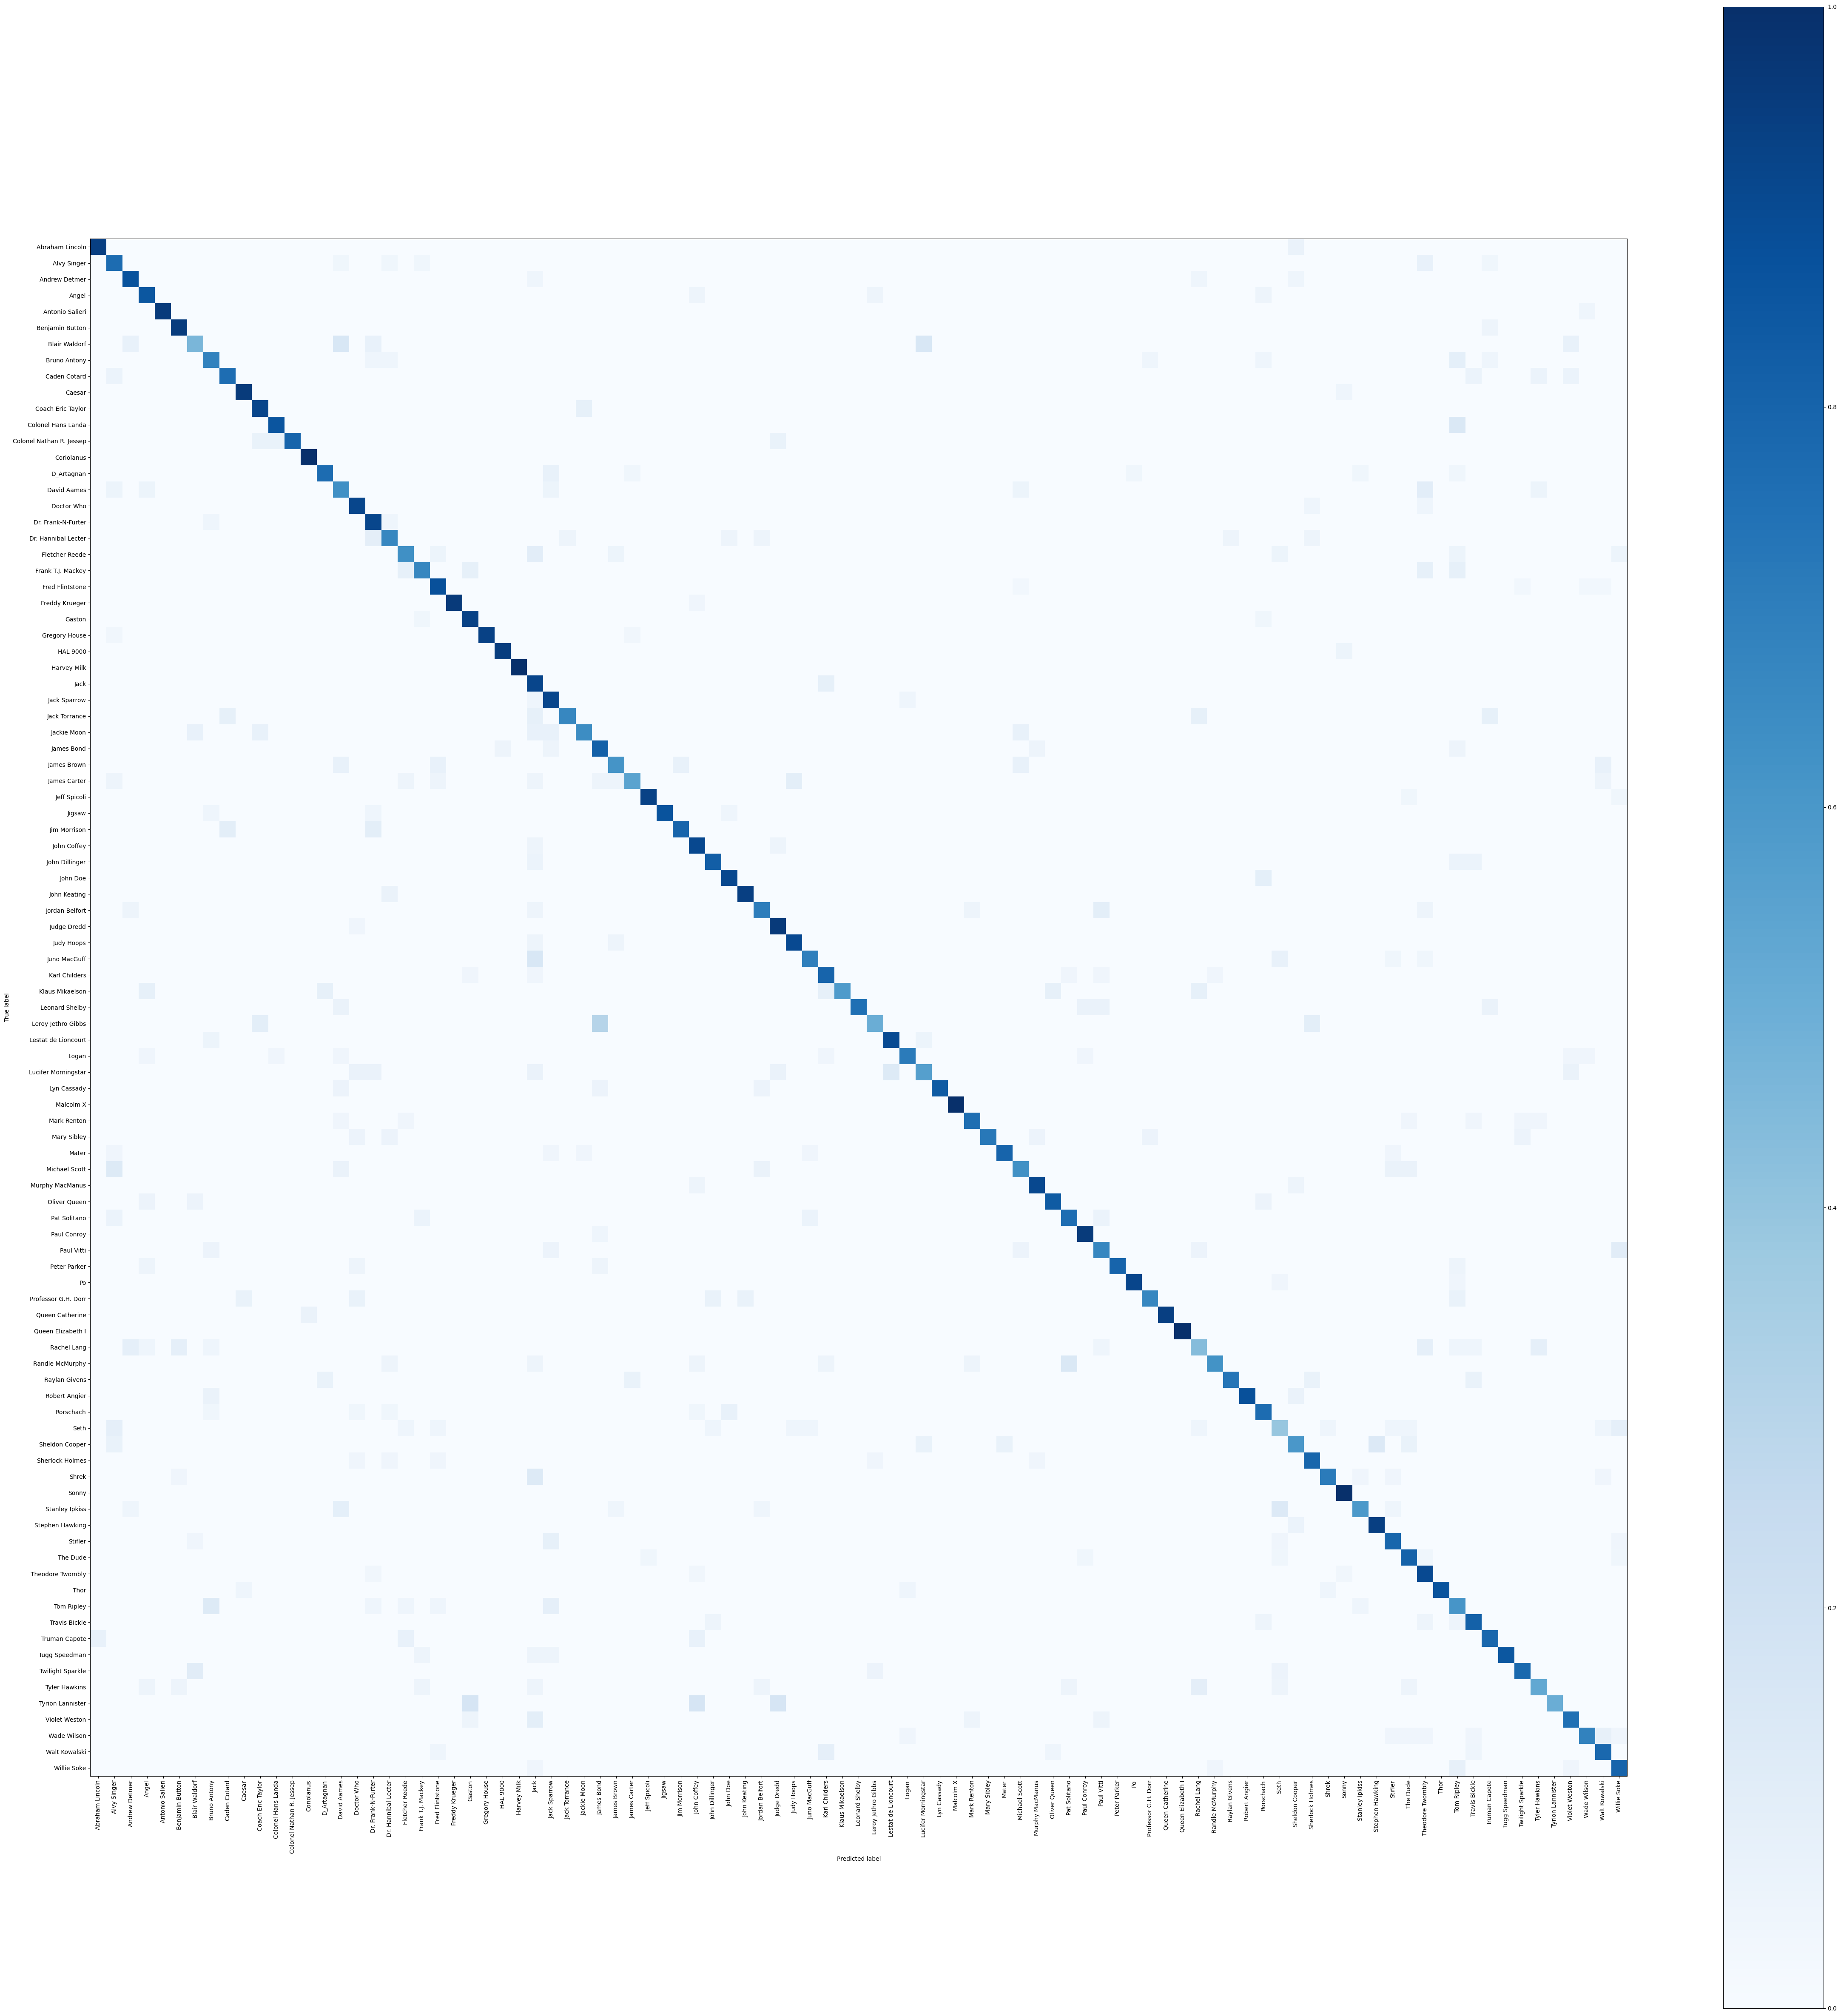

In [ ]:
fig_size_val = max(8, len(labels) * 0.5)
fig, ax = plt.subplots(figsize=(fig_size_val, fig_size_val))
labels = sorted(df["role_norm"].unique())
label_display_map = df.set_index("role_norm")["role"].to_dict()
display_labels = [label_display_map.get(l, l) for l in labels]

cmp = ConfusionMatrixDisplay.from_predictions(
    df["role_norm"], 
    df["pred_norm"], 
    labels=labels,
    display_labels=display_labels,
    normalize='true',
    include_values=False,
    cmap=plt.cm.Blues,
    xticks_rotation=90,
    ax=ax,
)

plt.tight_layout()
plt.show()